# Módulo 5 — Black-Scholes-Merton: a EDP, a fórmula e as gregas

## Introdução

O modelo de Black, Scholes e Merton, de 1973, é o ponto de referência de toda a teoria de derivativos. Ele supõe que o preço do ativo segue um movimento browniano geométrico, com volatilidade constante, e que se pode negociar continuamente sem custos.

Sob essas hipóteses, uma opção pode ser replicada de forma perfeita combinando o ativo e a conta remunerada, rebalanceando a carteira a cada instante. Dessa replicação sai uma **equação diferencial parcial** que o preço da opção precisa satisfazer, e nela a taxa de retorno esperada do ativo desaparece: o preço depende apenas da volatilidade. Resolvendo a equação, ou calculando a esperança neutra ao risco do Capítulo 4, obtém-se a **fórmula de Black-Scholes**.

As derivadas do preço em relação às variáveis do problema, as **gregas** (delta, gama, vega, theta e rô), medem as sensibilidades da opção e orientam o hedge. O capítulo deduz a equação, a fórmula e as gregas e verifica cada uma numericamente. Black-Scholes não é o modelo final deste livro, mas é a linguagem em que o mercado cota opções (pela volatilidade implícita) e o referencial contra o qual medimos os modelos mais ricos.

**Curso:** Derivativos com Python, a partir de *Derivatives Analytics with Python* (Y. Hilpisch, Wiley, 2015).
**Este módulo cobre:** seções 5.1 a 5.3 do livro. A árvore binomial (§5.4) fica para o Módulo 6.

## O que você vai conseguir fazer ao final

1. Deduzir a equação de Black-Scholes por replicação, sem supor neutralidade ao risco.
2. Deduzir a fórmula por dois caminhos independentes e ver por que eles coincidem.
3. Resolver a EDP numericamente, inclusive para payoffs sem fórmula.
4. Deduzir e usar as cinco gregas.
5. Explicar a relação entre gama, teta e volatilidade realizada.
6. Medir o que acontece quando se faz hedge com a volatilidade errada.

## Onde estamos

Nos módulos anteriores, a fórmula BSM foi caixa-preta. Agora temos as ferramentas para abri-la: Itô, replicação e medida neutra ao risco.

## 0. Preparação

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mpmath as mp
import sympy as sy
from scipy.linalg import solve_banded
from scipy.stats import norm
from IPython.display import display

AZUL, LARANJA, VERDE, CINZA = "#2a78d6", "#eb6834", "#1baf7a", "#8a8a84"
RAMPA3 = ["#86b6ef", "#2a78d6", "#0d366b"]

plt.rcParams.update({
    "figure.figsize": (7.2, 4.0), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5df", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "lines.linewidth": 2.0, "legend.frameon": False,
    "font.size": 10,
})


def f3(x):
    """Formata com três casas decimais no padrão brasileiro."""
    return f"{x:,.3f}".replace(",", "§").replace(".", ",").replace("§", ".")


def tabela(df):
    """Exibe um DataFrame com os números reais em três casas decimais."""
    def fmt(v):
        if isinstance(v, (float, np.floating)):
            return "n/d" if np.isnan(v) else f3(v)
        return v
    display(df.map(fmt))


_checks = {"n": 0}


def ok(condicao, mensagem):
    """Verificação do laboratório: interrompe o notebook se a conta não fechar."""
    assert bool(condicao), f"FALHOU: {mensagem}"
    _checks["n"] += 1
    print(f"OK — {mensagem}")


print("Ambiente pronto.")

Ambiente pronto.


---
## 1. O modelo

**Livro: §5.2.1**

Dois ativos negociados. O título sem risco cresce à taxa constante $r$:

$$dB_t = r B_t\,dt.$$

O índice segue um browniano geométrico. Partimos da dinâmica **real**, sob $P$, com retorno esperado $\mu$:

$$dS_t = \mu S_t\,dt + \sigma S_t\,dZ_t.$$

> O livro já parte da dinâmica neutra ao risco, com $r$ no lugar de $\mu$. Preferimos começar com $\mu$, porque assim a EDP mostra por si só que o retorno esperado não importa. Na dedução com $r$, esse resultado teria sido embutido na hipótese.

Hipóteses de mercado perfeito: negociação contínua, sem custos, sem restrições a posições, volatilidade e juros constantes, sem dividendos. Estamos num índice, e o tratamento de dividendos é o tema do Exercício 3.

---
## 2. A equação de Black-Scholes

**Livro: §5.2.2**

Queremos o valor de um direito cujo preço depende apenas de $S$ e $t$, $V(S, t)$.

### Passo 1: aplicar Itô a $V$

$$dV = \Big(V_t + \mu S V_S + \tfrac12\sigma^2S^2V_{SS}\Big)dt + \sigma S V_S\,dZ.$$

### Passo 2: montar a carteira replicante

Compramos $\phi_t$ unidades do índice e $\psi_t$ títulos, com valor $\Pi = \phi S + \psi B$. Pela condição de **autofinanciamento** (Módulo 3), a variação do valor vem só dos ganhos de mercado:

$$d\Pi = \phi\,dS + \psi\,dB = \big(\phi\mu S + \psi r B\big)dt + \phi\sigma S\,dZ.$$

### Passo 3: igualar os termos aleatórios

Queremos $\Pi = V$ em todos os instantes. Para os coeficientes de $dZ$ coincidirem:

$$\phi\,\sigma S = \sigma S\,V_S \quad\Longrightarrow\quad \boxed{\phi = V_S = \Delta.}$$

### Passo 4: igualar os termos em $dt$

Substituindo $\phi = V_S$:

$$V_S\mu S + \psi r B = V_t + \mu S V_S + \tfrac12\sigma^2S^2V_{SS}.$$

**O termo $\mu S V_S$ aparece nos dois lados e se cancela.** Sobra:

$$\psi r B = V_t + \tfrac12\sigma^2S^2V_{SS}.$$

### Passo 5: eliminar $\psi$

Como $\Pi = V$, temos $\psi B = V - S V_S$. Substituindo:

$$r(V - S V_S) = V_t + \tfrac12\sigma^2S^2V_{SS}.$$

Rearrumando, chegamos à **equação de Black-Scholes**:

$$\boxed{V_t + rS\,V_S + \tfrac12\sigma^2S^2\,V_{SS} - rV = 0.}$$

Observe três pontos:

1. $\mu$ **sumiu**. O motivo é o cancelamento do Passo 4: o hedge elimina a exposição à tendência.
2. A equação vale para **qualquer** derivativo cujo valor dependa só de $(S, t)$. O que distingue uma call de uma put é a condição final $V(S, T) = h(S)$.
3. O termo em $S$ tem coeficiente $r$, não $\mu$. Foi essa substituição que deu origem à ideia de precificação neutra ao risco.

> **Errata importante do livro.** Na passagem para a equação (5.6), o livro escreve $r\big(V - \partial V/\partial S\big)$ em vez de $r\big(V - S\,\partial V/\partial S\big)$, e a própria equação (5.6) está impressa sem o fator $rS$ no primeiro termo, como $\frac{\partial V}{\partial S} + \dots$. A forma correta é a do quadro acima. O Laboratório 2.1 mostra que a versão impressa não é satisfeita pela fórmula.

**Observação sobre a dedução do livro.** Ele usa a carteira $\Pi = V - \Delta S$ e trata $\Delta$ como constante no intervalo. Essa carteira não é autofinanciada, e a conta só funciona porque $\Delta$ é mantido fixo em $d\Pi$. O caminho por replicação, seguido acima, é o de Merton e dispensa esse cuidado.

### 2.1 Lendo a equação: gama e teta

Com $\Delta = V_S$, $\Gamma = V_{SS}$ e $\Theta = V_t$, temos

$$\Theta + \tfrac12\sigma^2S^2\Gamma = r\,(V - S\Delta).$$

Com juros zero, $\Theta = -\tfrac12\sigma^2S^2\Gamma$: **o que o titular ganha em convexidade, perde em passagem do tempo**. Veremos o significado disso em P&L na Seção 7.

### 2.2 Da EDP à esperança: Feynman-Kac

Aplique Itô a $e^{-rt}V(S_t,t)$ sob $Q$, em que $dS = rS\,dt + \sigma S\,dZ^Q$:

$$d\big(e^{-rt}V\big) = e^{-rt}\big(V_t + rSV_S + \tfrac12\sigma^2S^2V_{SS} - rV\big)dt + e^{-rt}\sigma SV_S\,dZ^Q.$$

O parêntese é a própria EDP, igual a zero. Sobra um martingale. Portanto $e^{-rt}V_t = \mathbb{E}^Q_t[e^{-rT}h(S_T)]$. **A EDP e a esperança são a mesma coisa, escrita de duas formas.** Este é o teorema de Feynman-Kac.

### Laboratório 2.1 — A fórmula satisfaz a EDP?

Escrevemos a fórmula de forma simbólica, derivamos e avaliamos o resíduo com 50 dígitos em pontos aleatórios.

In [2]:
S_s, K_s, tau_s, r_s, sig_s = sy.symbols("S K tau r sigma", positive=True)
d1_s = (sy.log(S_s / K_s) + (r_s + sig_s**2 / 2) * tau_s) / (sig_s * sy.sqrt(tau_s))
d2_s = d1_s - sig_s * sy.sqrt(tau_s)
N_s = lambda x: (1 + sy.erf(x / sy.sqrt(2))) / 2
C_s = S_s * N_s(d1_s) - K_s * sy.exp(-r_s * tau_s) * N_s(d2_s)

# Em t, com tau = T - t: V_t = -V_tau
Vt, Vs, Vss = -sy.diff(C_s, tau_s), sy.diff(C_s, S_s), sy.diff(C_s, S_s, 2)
correta = Vt + r_s * S_s * Vs + sig_s**2 * S_s**2 * Vss / 2 - r_s * C_s
impressa = Vs + sig_s**2 * S_s**2 * Vss / 2 + Vt - r_s * C_s

rng = np.random.default_rng(601)
linhas = []
for _ in range(6):
    p = {S_s: rng.uniform(50, 150), K_s: rng.uniform(50, 150), tau_s: rng.uniform(0.1, 2), r_s: rng.uniform(0.01, 0.1), sig_s: rng.uniform(0.1, 0.5)}
    linhas.append({"S": float(p[S_s]), "K": float(p[K_s]), "Resíduo na EDP correta": abs(float(correta.evalf(50, subs=p))), "Resíduo em (5.6) como impressa": abs(float(impressa.evalf(50, subs=p)))})
res = pd.DataFrame(linhas)
tabela(res)
ok((res["Resíduo na EDP correta"] < 1e-30).all(), "a fórmula BSM satisfaz a EDP com 50 dígitos")
ok((res["Resíduo em (5.6) como impressa"] > 1e-3).all(), "a equação como impressa no livro não é satisfeita")

,S,K,Resíduo na EDP correta,Resíduo em (5.6) como impressa
0,"132,546","50,277","0,000","9,666"
1,"110,102","108,779","0,000","2,151"
2,"98,423","98,129","0,000","5,143"
3,"108,703","116,086","0,000","2,807"
4,"118,032","51,157","0,000","9,989"
5,"67,668","51,857","0,000","1,681"


OK — a fórmula BSM satisfaz a EDP com 50 dígitos
OK — a equação como impressa no livro não é satisfeita


---
## 3. A fórmula, por dois caminhos

**Livro: §5.2.3**

### Caminho A: integrando a esperança

Para uma call com prazo restante $\tau = T - t$, sob $Q$:

$$S_T = S\exp\big[(r - \tfrac12\sigma^2)\tau + \sigma\sqrt\tau\,z\big], \quad z\sim N(0,1).$$

**Passo 1: quando a call paga?** $S_T > K$ equivale a $z > -d_2$, com

$$d_2 = \frac{\ln(S/K) + (r - \tfrac12\sigma^2)\tau}{\sigma\sqrt\tau}.$$

**Passo 2: separar o valor em dois termos.**

$$C = e^{-r\tau}\int_{-d_2}^{\infty}\big(S_T(z) - K\big)\varphi(z)\,dz = \underbrace{e^{-r\tau}\int_{-d_2}^\infty S_T(z)\varphi(z)\,dz}_{\text{I}} - \underbrace{Ke^{-r\tau}\int_{-d_2}^\infty\varphi(z)\,dz}_{\text{II}}.$$

**Passo 3: termo II.** Pela simetria da normal, $\int_{-d_2}^\infty\varphi = N(d_2)$. Logo, $\text{II} = Ke^{-r\tau}N(d_2)$.

**Passo 4: termo I.** Substituindo $S_T$, o fator $e^{-r\tau}$ cancela $e^{r\tau}$:

$$\text{I} = S\int_{-d_2}^\infty \exp\big(-\tfrac12\sigma^2\tau + \sigma\sqrt\tau\,z - \tfrac12z^2\big)\frac{dz}{\sqrt{2\pi}}.$$

**Completando o quadrado**, $-\tfrac12\sigma^2\tau + \sigma\sqrt\tau z - \tfrac12z^2 = -\tfrac12(z - \sigma\sqrt\tau)^2$. Com $w = z - \sigma\sqrt\tau$:

$$\text{I} = S\int_{-d_2-\sigma\sqrt\tau}^\infty\varphi(w)\,dw = S\,N(d_2 + \sigma\sqrt\tau) = S\,N(d_1).$$

**Resultado:**

$$\boxed{C = S\,N(d_1) - Ke^{-r\tau}N(d_2), \qquad d_1 = d_2 + \sigma\sqrt\tau.}$$

**O significado de $N(d_1)$.** No Passo 4, o que apareceu foi a densidade reponderada pelo fator $S_T/(Se^{r\tau})$. É uma mudança de medida de Girsanov: é a medida em que o **índice é o numerário**. Assim, $N(d_2)$ é a probabilidade de exercício sob $Q$, e $N(d_1)$ é a probabilidade de exercício sob a medida do índice.

### Caminho B: resolvendo a EDP

**Passo 1: variável de tempo restante.** Com $\tau = T - t$, temos $V_t = -V_\tau$, e o problema vira uma condição **inicial** $V(S, 0) = h(S)$.

**Passo 2: tirar o desconto e o drift.** Mude variáveis:

$$V(S,\tau) = e^{-r\tau}u(x,\tau), \qquad x = \ln S + (r - \tfrac12\sigma^2)\tau.$$

**Passo 3: calcular as derivadas**, pela regra da cadeia:

$$V_\tau = e^{-r\tau}\big[-ru + u_\tau + (r - \tfrac12\sigma^2)u_x\big], \quad V_S = e^{-r\tau}\frac{u_x}{S}, \quad V_{SS} = e^{-r\tau}\frac{u_{xx} - u_x}{S^2}.$$

**Passo 4: substituir** em $V_\tau = rSV_S + \tfrac12\sigma^2S^2V_{SS} - rV$:

$$-ru + u_\tau + (r - \tfrac12\sigma^2)u_x = ru_x + \tfrac12\sigma^2(u_{xx} - u_x) - ru.$$

Tudo se cancela, exceto:

$$\boxed{u_\tau = \tfrac12\sigma^2\,u_{xx}.}$$

É a **equação do calor**: a BSM é difusão pura depois da mudança de variáveis.

**Passo 5: solução.** A solução da equação do calor é a convolução da condição inicial com um núcleo gaussiano:

$$u(x,\tau) = \int_{-\infty}^\infty h(e^y)\,\frac{1}{\sqrt{2\pi\sigma^2\tau}}\exp\Big[-\frac{(x-y)^2}{2\sigma^2\tau}\Big]dy.$$

Com $y = x + \sigma\sqrt\tau\,z$, tem-se $e^y = S\exp[(r - \tfrac12\sigma^2)\tau + \sigma\sqrt\tau z]$. **É exatamente a integral do Caminho A.** Duas teorias, uma só conta.

### A put

Compre índice e put, e venda a call. Em $T$ o resultado é $K$ em qualquer cenário: se $S_T < K$, tem-se $S_T + (K - S_T)$; se $S_T \ge K$, tem-se $S_T - (S_T - K)$. Logo, $S + P - C = Ke^{-r\tau}$, de onde, usando $1 - N(x) = N(-x)$,

$$P = Ke^{-r\tau}N(-d_2) - S\,N(-d_1).$$

### Laboratório 3.1 — Verificações

A opção de referência do livro: $S_0 = K = 100$, $T = 1$, $r = 5\%$, $\sigma = 20\%$.

In [3]:
def d12(S, K, tau, r, sig):
    d1 = (np.log(S / K) + (r + 0.5 * sig**2) * tau) / (sig * np.sqrt(tau))
    return d1, d1 - sig * np.sqrt(tau)


def bsm(S, K, tau, r, sig, tipo="call"):
    d1, d2 = d12(S, K, tau, r, sig)
    if tipo == "call":
        return S * norm.cdf(d1) - K * np.exp(-r * tau) * norm.cdf(d2)
    return K * np.exp(-r * tau) * norm.cdf(-d2) - S * norm.cdf(-d1)


S0, K0, T0, r0, s0 = 100.0, 100.0, 1.0, 0.05, 0.20
C0, P0 = float(bsm(S0, K0, T0, r0, s0)), float(bsm(S0, K0, T0, r0, s0, "put"))

rng = np.random.default_rng(602)
n = 4_000_000
z = rng.standard_normal(n)
ST = S0 * np.exp((r0 - 0.5 * s0**2) * T0 + s0 * np.sqrt(T0) * z)
amostra = np.exp(-r0 * T0) * np.maximum(ST - K0, 0)
ep = amostra.std(ddof=1) / np.sqrt(n)

d1, d2 = d12(S0, K0, T0, r0, s0)
peso = ST / (S0 * np.exp(r0 * T0))
tabela(pd.DataFrame([
    {"Grandeza": "Call pela fórmula", "Valor": C0},
    {"Grandeza": "Call por Monte Carlo", "Valor": float(amostra.mean())},
    {"Grandeza": "Put pela fórmula", "Valor": P0},
    {"Grandeza": "C − P", "Valor": C0 - P0},
    {"Grandeza": "S − K·exp(−rT)", "Valor": S0 - K0 * np.exp(-r0 * T0)},
    {"Grandeza": "N(d2)", "Valor": float(norm.cdf(d2))},
    {"Grandeza": "P(S_T>K) sob Q, simulada", "Valor": float((ST > K0).mean())},
    {"Grandeza": "N(d1)", "Valor": float(norm.cdf(d1))},
    {"Grandeza": "P(S_T>K) sob a medida do índice, simulada", "Valor": float(np.mean(peso * (ST > K0)))},
]))
ok(abs(C0 - 10.450584) < 1e-5 and abs(P0 - 5.573526) < 1e-5, "valores coincidem com a referência do livro (cerca de 10,4 e 5,6)")
ok(abs(amostra.mean() - C0) < 4 * ep, "Monte Carlo confere com a fórmula")
ok(abs((C0 - P0) - (S0 - K0 * np.exp(-r0 * T0))) < 1e-10, "paridade put-call")
ok(abs((ST > K0).mean() - norm.cdf(d2)) < 0.001, "N(d2) é a probabilidade de exercício sob Q")
ok(abs(np.mean(peso * (ST > K0)) - norm.cdf(d1)) < 0.001, "N(d1) é a probabilidade de exercício sob a medida do índice")

,Grandeza,Valor
0,Call pela fórmula,"10,451"
1,Call por Monte Carlo,"10,444"
2,Put pela fórmula,"5,574"
3,C − P,"4,877"
4,S − K·exp(−rT),"4,877"
5,N(d2),"0,560"
6,"P(S_T>K) sob Q, simulada","0,560"
7,N(d1),"0,637"
8,"P(S_T>K) sob a medida do índice, simulada","0,637"


OK — valores coincidem com a referência do livro (cerca de 10,4 e 5,6)


OK — Monte Carlo confere com a fórmula
OK — paridade put-call
OK — N(d2) é a probabilidade de exercício sob Q
OK — N(d1) é a probabilidade de exercício sob a medida do índice


### Laboratório 3.2 — Dependência dos parâmetros

Reproduzimos as Figuras 5.1 e 5.2 do livro em um único painel. Note como o valor da put cai para prazos longos, quando dentro do dinheiro, e como o sinal do efeito dos juros difere entre call e put.

> **Errata menor:** no item 1 da lista do livro, "*K > 100 for the put, OTM*" deveria ser $K < 100$.

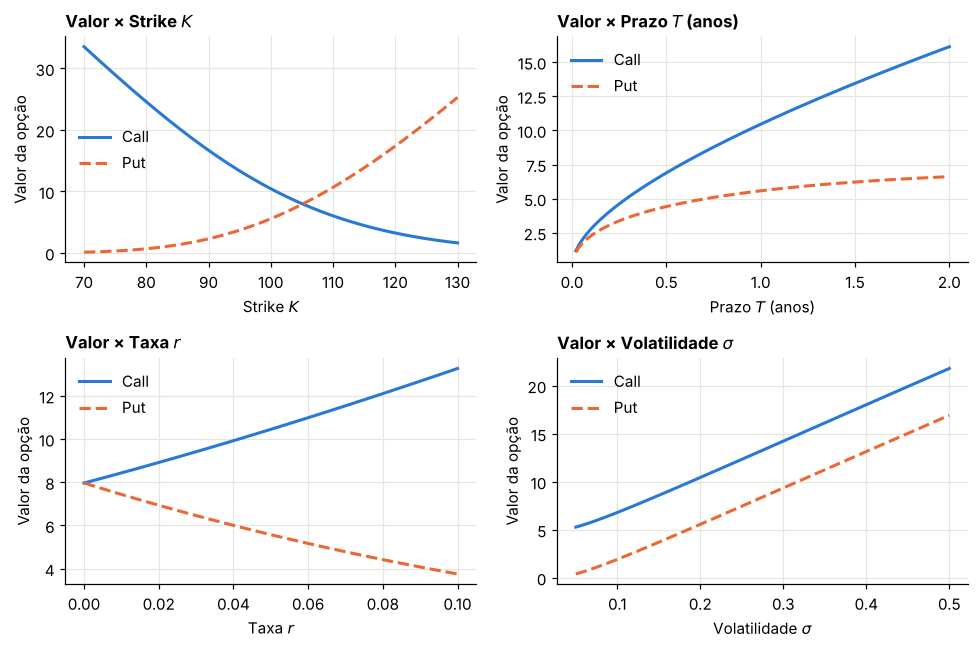

OK — put europeia bem dentro do dinheiro pode perder valor com o prazo


In [4]:
base = dict(S=S0, K=K0, tau=T0, r=r0, sig=s0)
grades = {
    "K": (np.linspace(70, 130, 121), "Strike $K$"),
    "tau": (np.linspace(0.02, 2.0, 100), "Prazo $T$ (anos)"),
    "r": (np.linspace(0.0, 0.10, 100), "Taxa $r$"),
    "sig": (np.linspace(0.05, 0.5, 100), "Volatilidade $\\sigma$"),
}
fig, eixos = plt.subplots(2, 2, figsize=(9, 6))
for ax, (par, (g, rot)) in zip(eixos.ravel(), grades.items()):
    c = np.array([float(bsm(**{**base, par: v})) for v in g])
    p = np.array([float(bsm(**{**base, par: v}, tipo="put")) for v in g])
    ax.plot(g, c, color=AZUL, label="Call")
    ax.plot(g, p, color=LARANJA, ls="--", label="Put")
    ax.set_title(f"Valor × {rot}")
    ax.set_xlabel(rot)
    ax.set_ylabel("Valor da opção")
    ax.legend()
plt.tight_layout()
plt.show()

prazos = np.linspace(0.05, 30, 300)
put_itm = bsm(50.0, 100.0, prazos, 0.05, 0.2, "put")
ok(put_itm[-1] < put_itm[0], "put europeia bem dentro do dinheiro pode perder valor com o prazo")

---
## 4. Resolvendo a EDP no computador

**Conteúdo além do livro; útil para payoffs sem fórmula**

### 4.1 Montagem em log-preço

Com $x = \ln S$ e prazo restante $\tau$, a EDP vira

$$V_\tau = aV_{xx} + bV_x - rV, \qquad a = \tfrac12\sigma^2, \quad b = r - \tfrac12\sigma^2.$$

Numa malha com passo $\Delta x$, aproximamos as derivadas por diferenças centrais. Em cada ponto interior:

$$\mathcal{L}V_j = \ell V_{j-1} + c V_j + u V_{j+1}, \quad \ell = \frac{a}{\Delta x^2} - \frac{b}{2\Delta x}, \quad c = -\frac{2a}{\Delta x^2} - r, \quad u = \frac{a}{\Delta x^2} + \frac{b}{2\Delta x}.$$

### 4.2 Crank-Nicolson

A média entre os passos de tempo $n$ e $n+1$ dá erro de segunda ordem:

$$\Big(I - \frac{\Delta\tau}{2}\mathcal{L}\Big)V^{n+1} = \Big(I + \frac{\Delta\tau}{2}\mathcal{L}\Big)V^n.$$

Em cada passo, resolve-se um sistema **tridiagonal**, de custo linear.

**Cuidado: a quina do payoff.** Crank-Nicolson não amortece oscilações de alta frequência, e a quina em $K$ as gera. A solução usual, de **Rannacher**, troca os primeiros passos por passos implícitos, que suavizam a condição inicial.

Nas bordas, usamos o comportamento assintótico: para uma call, $V \to 0$ embaixo e $V \to S - Ke^{-r\tau}$ em cima.

### Laboratório 4.1 — Convergência e gregas de graça

Colocamos o nó central exatamente em $\ln S_0$ e, ao dobrar a malha, medimos o erro. Em segunda ordem, o erro deve cair por um fator próximo de 4.

,Malha J,Valor numérico,Erro,Razão do erro
0,100,"10,447","0,003",n/d
1,200,"10,450","0,001","4,002"
2,400,"10,450","0,000","4,001"
3,800,"10,451","0,000","4,000"
4,1600,"10,451","0,000","4,000"


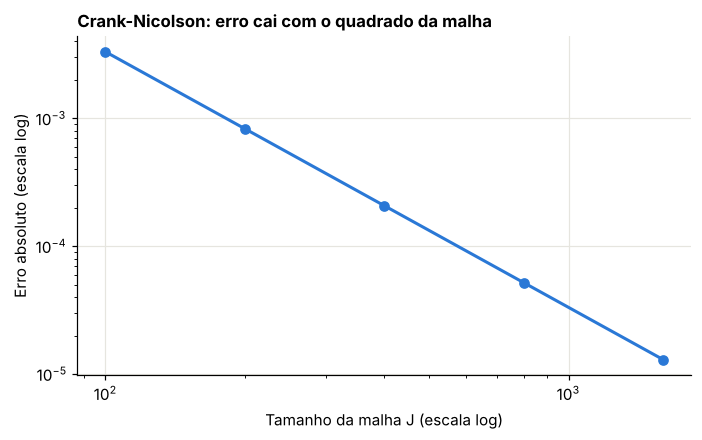

OK — convergência de segunda ordem
OK — o erro final é menor que 0,001


,Grega,Malha da EDP,Fórmula
0,Delta,"0,637","0,637"
1,Gama,"0,019","0,019"


OK — delta e gama saem da própria malha


In [5]:
def cn(payoff, borda, S0, K, T, r, sig, J, nt, rannacher=4):
    """Crank-Nicolson em log-preço, com passos implícitos iniciais. Devolve malha e valores."""
    L = 6 * sig * np.sqrt(T) + abs(np.log(K / S0))
    dx = L / J
    x = np.log(S0) + dx * np.arange(-J, J + 1)
    Sg = np.exp(x)
    V = payoff(Sg)
    a, b = 0.5 * sig**2, r - 0.5 * sig**2
    l_, c_, u_ = a / dx**2 - b / (2 * dx), -2 * a / dx**2 - r, a / dx**2 + b / (2 * dx)
    dtau = T / nt
    passos = [(dtau / 2, 1.0)] * rannacher + [(dtau, 0.5)] * (nt - rannacher // 2)
    tau = 0.0
    for h, th in passos:
        tau_novo = tau + h
        lo, hi = borda(Sg[0], tau_novo), borda(Sg[-1], tau_novo)
        lo_v, hi_v = borda(Sg[0], tau), borda(Sg[-1], tau)
        interior = V[1:-1]
        rhs = interior + (1 - th) * h * (l_ * V[:-2] + c_ * interior + u_ * V[2:])
        rhs[0] += th * h * l_ * lo
        rhs[-1] += th * h * u_ * hi
        ab = np.zeros((3, interior.size))
        ab[0, 1:] = -th * h * u_
        ab[1, :] = 1 - th * h * c_
        ab[2, :-1] = -th * h * l_
        novo = solve_banded((1, 1), ab, rhs)
        V = np.r_[lo, novo, hi]
        tau = tau_novo
    return x, V, J, dx


pay_call = lambda S: np.maximum(S - K0, 0.0)
borda_call = lambda S, tau: 0.0 if S < K0 else S - K0 * np.exp(-r0 * tau)

linhas = []
for J in [100, 200, 400, 800, 1600]:
    x, V, c_, dx = cn(pay_call, borda_call, S0, K0, T0, r0, s0, J, J)
    linhas.append({"Malha J": J, "Valor numérico": float(V[c_]), "Erro": abs(float(V[c_]) - C0)})
conv = pd.DataFrame(linhas)
conv["Razão do erro"] = conv["Erro"].shift(1) / conv["Erro"]
tabela(conv)

fig, ax = plt.subplots()
ax.loglog(conv["Malha J"], conv["Erro"], color=AZUL, marker="o", markersize=6)
ax.set_title("Crank-Nicolson: erro cai com o quadrado da malha")
ax.set_xlabel("Tamanho da malha J (escala log)")
ax.set_ylabel("Erro absoluto (escala log)")
plt.show()

ok(3.2 < conv["Razão do erro"].iloc[-1] < 4.8, "convergência de segunda ordem")
ok(conv["Erro"].iloc[-1] < 1e-3, "o erro final é menor que 0,001")

# Gregas a partir da malha
J = 1600
x, V, c_, dx = cn(pay_call, borda_call, S0, K0, T0, r0, s0, J, J)
Vx = (V[c_ + 1] - V[c_ - 1]) / (2 * dx)
Vxx = (V[c_ + 1] - 2 * V[c_] + V[c_ - 1]) / dx**2
delta_pde = Vx / S0
gama_pde = (Vxx - Vx) / S0**2
d1, _ = d12(S0, K0, T0, r0, s0)
tabela(pd.DataFrame([
    {"Grega": "Delta", "Malha da EDP": float(delta_pde), "Fórmula": float(norm.cdf(d1))},
    {"Grega": "Gama", "Malha da EDP": float(gama_pde), "Fórmula": float(norm.pdf(d1) / (S0 * s0 * np.sqrt(T0)))},
]))
ok(abs(delta_pde - norm.cdf(d1)) < 1e-4 and abs(gama_pde - norm.pdf(d1) / (S0 * s0 * np.sqrt(T0))) < 1e-4, "delta e gama saem da própria malha")

### Laboratório 4.2 — Um payoff diferente

A mesma EDP resolve qualquer payoff que dependa apenas de $S_T$: basta trocar a condição final. Testamos com uma **digital** de 1 mês, que paga 1 se $S_T > K$, cuja solução é $e^{-r\tau}N(d_2)$. Usamos passos de tempo grandes de propósito, para expor o problema: em descontinuidades, é ainda mais importante amortecer os primeiros passos. A coluna conta quantas vezes a curva de valores muda de direção; o valor correto é monotônico.

In [6]:
pay_dig = lambda S: np.where(S > K0, 1.0, np.where(np.isclose(S, K0), 0.5, 0.0))
borda_dig = lambda S, tau: 0.0 if S < K0 else float(np.exp(-r0 * tau))
T_dig = 1 / 12
ref_dig = float(np.exp(-r0 * T_dig) * norm.cdf(d12(S0, K0, T_dig, r0, s0)[1]))

linhas = []
for ran, nome in [(0, "Crank-Nicolson puro"), (4, "Com passos implícitos iniciais")]:
    x, V, c_, dx = cn(pay_dig, borda_dig, S0, K0, T_dig, r0, s0, 800, 20, rannacher=ran)
    osc = int(np.sum(np.diff(np.sign(np.diff(V))) != 0))
    linhas.append({"Esquema": nome, "Valor": float(V[c_]), "Fórmula": ref_dig, "Erro": abs(float(V[c_]) - ref_dig), "Mudanças de direção na malha": osc})
d_ = pd.DataFrame(linhas).set_index("Esquema")
tabela(d_.reset_index())
ok(d_.loc["Com passos implícitos iniciais", "Erro"] < 2e-3, "o solver numérico reproduz a digital")
ok(d_.loc["Crank-Nicolson puro", "Mudanças de direção na malha"] > d_.loc["Com passos implícitos iniciais", "Mudanças de direção na malha"], "sem amortecimento, a solução oscila perto do strike")
ok(d_.loc["Crank-Nicolson puro", "Erro"] > 100 * d_.loc["Com passos implícitos iniciais", "Erro"], "sem amortecimento, o erro no strike é enorme")

,Esquema,Valor,Fórmula,Erro,Mudanças de direção na malha
0,Crank-Nicolson puro,"0,898","0,515","0,383",4
1,Com passos implícitos iniciais,"0,517","0,515","0,001",0


OK — o solver numérico reproduz a digital
OK — sem amortecimento, a solução oscila perto do strike
OK — sem amortecimento, o erro no strike é enorme


---
## 5. As gregas

**Livro: §5.3**

As gregas medem a sensibilidade do valor aos parâmetros. Usamos a identidade do Módulo 2, que simplifica tudo:

$$S\,\varphi(d_1) = Ke^{-r\tau}\varphi(d_2).$$

### Delta

$$\frac{\partial C}{\partial S} = N(d_1) + \big[S\varphi(d_1) - Ke^{-r\tau}\varphi(d_2)\big]\frac{\partial d_1}{\partial S} = N(d_1).$$

O colchete é zero pela identidade. (Usamos também $\partial d_2/\partial S = \partial d_1/\partial S$.) Para a put, pela paridade, $\Delta_P = \Delta_C - 1 = -N(-d_1)$.

### Gama

$$\Gamma = \frac{\partial\Delta}{\partial S} = \varphi(d_1)\frac{\partial d_1}{\partial S} = \frac{\varphi(d_1)}{S\sigma\sqrt\tau}.$$

Pela paridade, é igual para call e put.

### Vega

Como visto no Módulo 2: $\mathcal{V} = S\varphi(d_1)\sqrt\tau$. É igual para call e put.

### Rô

$\partial C/\partial r$ recebe duas contribuições. O colchete com a identidade se cancela outra vez, e sobra a derivada do desconto: $\rho_C = K\tau e^{-r\tau}N(d_2)$. Para a put, $\rho_P = -K\tau e^{-r\tau}N(-d_2)$.

### Teta

Em vez de derivar de novo, usamos a própria EDP: $\Theta = rC - rS\Delta - \tfrac12\sigma^2S^2\Gamma$. Substituindo:

$$\Theta_C = -\frac{S\varphi(d_1)\sigma}{2\sqrt\tau} - rKe^{-r\tau}N(d_2).$$

Para a put: $\Theta_P = -\dfrac{S\varphi(d_1)\sigma}{2\sqrt\tau} + rKe^{-r\tau}N(-d_2)$.

O teta é a variação do valor por unidade de tempo decorrido. Para uma call, é sempre negativo com $r \ge 0$. Para uma put bem dentro do dinheiro, pode ser positivo, resultado do valor no tempo negativo do Módulo 1.

### Onde o gama é máximo

O senso comum diz que no dinheiro. Vamos conferir. Derivando $\ln\Gamma = \ln\varphi(d_1) - \ln S - \ln(\sigma\sqrt\tau)$ em relação a $S$:

$$-d_1\frac{1}{S\sigma\sqrt\tau} - \frac1S = 0 \quad\Longrightarrow\quad d_1 = -\sigma\sqrt\tau \quad\Longrightarrow\quad S^* = K\exp\big[-(r + \tfrac32\sigma^2)\tau\big].$$

Próximo do strike para prazos curtos, mas abaixo dele para prazos longos.

### Laboratório 5.1 — Fórmulas contra diferenças finitas

In [7]:
def gregas(S, K, tau, r, sig, tipo="call"):
    d1, d2 = d12(S, K, tau, r, sig)
    gama = norm.pdf(d1) / (S * sig * np.sqrt(tau))
    vega = S * norm.pdf(d1) * np.sqrt(tau)
    decaimento = -S * norm.pdf(d1) * sig / (2 * np.sqrt(tau))
    if tipo == "call":
        return {"delta": norm.cdf(d1), "gama": gama, "teta": decaimento - r * K * np.exp(-r * tau) * norm.cdf(d2), "ro": K * tau * np.exp(-r * tau) * norm.cdf(d2), "vega": vega}
    return {"delta": norm.cdf(d1) - 1, "gama": gama, "teta": decaimento + r * K * np.exp(-r * tau) * norm.cdf(-d2), "ro": -K * tau * np.exp(-r * tau) * norm.cdf(-d2), "vega": vega}


def dif_finita(S, K, tau, r, sig, tipo):
    f = lambda **k: float(bsm(**{**dict(S=S, K=K, tau=tau, r=r, sig=sig), **k}, tipo=tipo))
    h = 1e-4
    return {
        "delta": (f(S=S + h) - f(S=S - h)) / (2 * h),
        "gama": (f(S=S + 1e-2) - 2 * f() + f(S=S - 1e-2)) / 1e-4,
        "teta": -(f(tau=tau + h) - f(tau=tau - h)) / (2 * h),
        "ro": (f(r=r + h) - f(r=r - h)) / (2 * h),
        "vega": (f(sig=sig + h) - f(sig=sig - h)) / (2 * h),
    }


pontos = [(100.0, 100.0, 1.0), (90.0, 100.0, 0.25), (120.0, 100.0, 2.0)]
linhas = []
maior = 0.0
for tipo in ("call", "put"):
    for S_, K_, t_ in pontos:
        a, b = gregas(S_, K_, t_, r0, s0, tipo), dif_finita(S_, K_, t_, r0, s0, tipo)
        maior = max(maior, max(abs(float(a[k]) - b[k]) for k in a))
        linhas.append({"Tipo": tipo, "S": S_, "Prazo": t_, **{k: float(v) for k, v in a.items()}})
tabela(pd.DataFrame(linhas))
print("Maior diferença entre fórmula e diferenças finitas:", f3(maior))
ok(maior < 1e-3, "as fórmulas das gregas coincidem com as diferenças finitas")

d = gregas(S0, K0, T0, r0, s0)
ok(abs(float(d["teta"]) - (r0 * C0 - r0 * S0 * float(d["delta"]) - 0.5 * s0**2 * S0**2 * float(d["gama"]))) < 1e-10, "o teta é o que a EDP determina")
ok(float(gregas(40.0, 100.0, 1.0, 0.05, 0.2, "put")["teta"]) > 0, "put bem dentro do dinheiro tem teta positivo")

Sg = np.linspace(50, 160, 2201)
for tau_ in [1 / 12, 1.0, 2.0]:
    g_ = gregas(Sg, 100.0, tau_, 0.05, 0.3)["gama"]
    ok(abs(Sg[np.argmax(g_)] - 100.0 * np.exp(-(0.05 + 1.5 * 0.3**2) * tau_)) < 0.1, f"pico do gama em S* para prazo {f3(tau_)}")

,Tipo,S,Prazo,delta,gama,teta,ro,vega
0,call,"100,000","1,000","0,637","0,019","-6,414","53,232","37,524"
1,call,"90,000","0,250","0,190","0,030","-5,691","4,046","12,204"
2,call,"120,000","2,000","0,873","0,006","-5,407","145,535","35,368"
3,put,"100,000","1,000","-0,363","0,019","-1,658","-41,890","37,524"
4,put,"90,000","0,250","-0,810","0,030","-0,753","-20,643","12,204"
5,put,"120,000","2,000","-0,127","0,006","-0,883","-35,433","35,368"


Maior diferença entre fórmula e diferenças finitas: 0,000
OK — as fórmulas das gregas coincidem com as diferenças finitas
OK — o teta é o que a EDP determina
OK — put bem dentro do dinheiro tem teta positivo
OK — pico do gama em S* para prazo 0,083
OK — pico do gama em S* para prazo 1,000
OK — pico do gama em S* para prazo 2,000


### Laboratório 5.2 — O formato das gregas

Em vez das superfícies 3D do livro, usamos fatias por prazo, para comparar os formatos na mesma escala de índice.

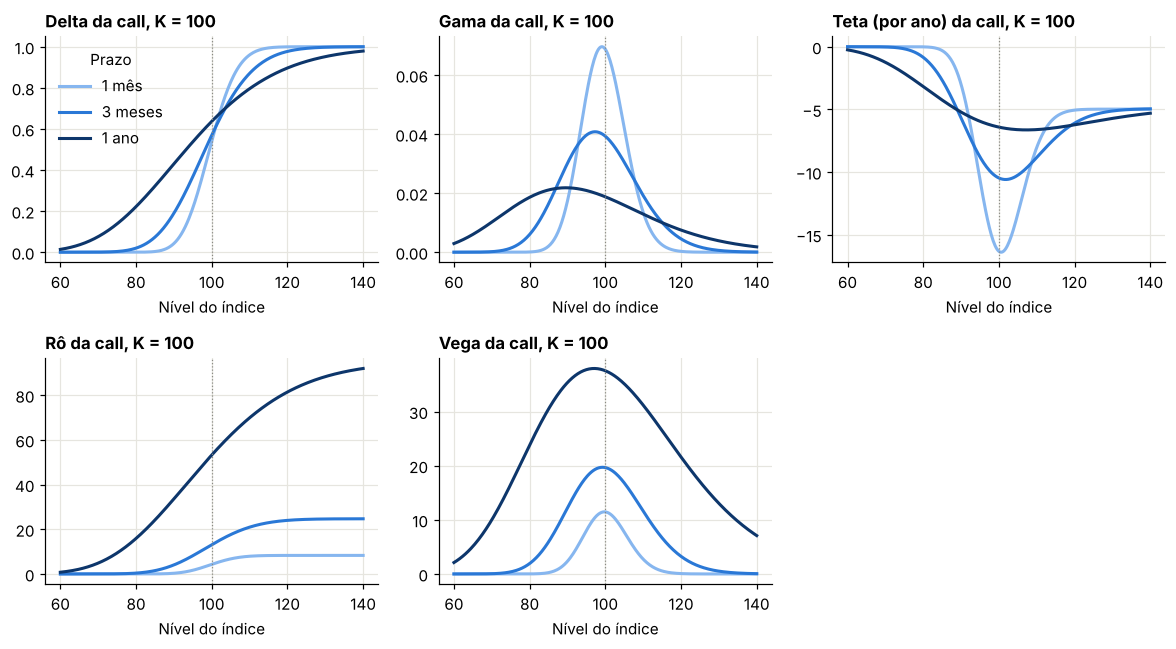

In [8]:
Sg = np.linspace(60, 140, 321)
prazos_g = [(1 / 12, "1 mês"), (0.25, "3 meses"), (1.0, "1 ano")]
fig, eixos = plt.subplots(2, 3, figsize=(10.8, 6))
eixos = eixos.ravel()
nomes = {"delta": "Delta", "gama": "Gama", "teta": "Teta (por ano)", "ro": "Rô", "vega": "Vega"}
for ax, (k, rot) in zip(eixos, nomes.items()):
    for (t_, nome), cor in zip(prazos_g, RAMPA3):
        ax.plot(Sg, gregas(Sg, 100.0, t_, r0, s0)[k], color=cor, label=nome)
    ax.set_title(f"{rot} da call, K = 100")
    ax.set_xlabel("Nível do índice")
    ax.axvline(100, color=CINZA, lw=0.8, ls=":")
eixos[0].legend(title="Prazo")
eixos[5].axis("off")
plt.tight_layout()
plt.show()

**Leitura.** O gama e o teta se concentram perto do strike nos prazos curtos: são os riscos do vencimento próximo. O vega e o rô crescem com o prazo.

---
## 6. Aproximação por gregas

Uma expansão de Taylor em todas as variáveis, até segunda ordem nos termos relevantes, é:

$$\Delta V \approx \Delta\,dS + \tfrac12\Gamma\,dS^2 + \mathcal{V}\,d\sigma + \tfrac12\text{Volga}\,d\sigma^2 + \text{Vanna}\,dS\,d\sigma + \Theta\,dt + \rho\,dr.$$

As duas gregas cruzadas são

$$\text{Vanna} = \frac{\partial^2 V}{\partial S\,\partial\sigma} = -\varphi(d_1)\frac{d_2}{\sigma}, \qquad \text{Volga} = \frac{\partial^2V}{\partial\sigma^2} = \mathcal{V}\,\frac{d_1d_2}{\sigma}.$$

No Módulo 1, a aproximação linear errou feio no cenário de crash. Vamos ver o quanto cada termo recupera. A abordagem padronizada do FRTB segue a mesma lógica com delta, vega e curvatura; lá, a curvatura é calculada por reprecificação sob choque, justamente porque a expansão falha em movimentos grandes.

### Laboratório 6.1 — Quanto cada termo explica

In [9]:
K_, S_, t_, r_, s_ = 8000.0, 8000.0, 1.0, 0.025, 0.20
d1, d2 = d12(S_, K_, t_, r_, s_)
g0 = {k: float(v) for k, v in gregas(S_, K_, t_, r_, s_).items()}
vanna = float(-norm.pdf(d1) * d2 / s_)
volga = float(g0["vega"] * d1 * d2 / s_)
v0 = float(bsm(S_, K_, t_, r_, s_))

cenarios = {"Índice −1%": (-80.0, 0.0), "Índice −10%": (-800.0, 0.0), "Vol +5 p.p.": (0.0, 0.05), "Crash: −20% e vol +15 p.p.": (-1600.0, 0.15)}
linhas = []
for nome, (dS, ds) in cenarios.items():
    completa = float(bsm(S_ + dS, K_, t_, r_, s_ + ds)) - v0
    primeira = g0["delta"] * dS + g0["vega"] * ds
    com_gama = primeira + 0.5 * g0["gama"] * dS**2
    completa2 = com_gama + 0.5 * volga * ds**2 + vanna * dS * ds
    linhas.append({"Cenário": nome, "Reprecificação": completa, "1ª ordem": primeira, "+ Gama": com_gama, "+ Volga e Vanna": completa2, "Erro final": completa2 - completa})
tay = pd.DataFrame(linhas).set_index("Cenário")
tabela(tay.reset_index())
nom, med = "Crash: −20% e vol +15 p.p.", "Índice −10%"
ok(abs(tay.loc[med, "Erro final"]) < 0.1 * abs(tay.loc[med, "1ª ordem"] - tay.loc[med, "Reprecificação"]), "em choque moderado, a segunda ordem recupera mais de 90% do erro")
ok(abs(tay.loc[nom, "Erro final"]) > 100, "no crash, a expansão continua errando muito")

,Cenário,Reprecificação,1ª ordem,+ Gama,+ Volga e Vanna,Erro final
0,Índice −1%,"-46,337","-47,121","-46,343","-46,343","-0,005"
1,Índice −10%,"-389,352","-471,208","-393,414","-393,414","-4,062"
2,Vol +5 p.p.,"155,621","155,588","155,588","155,698","0,077"
3,Crash: −20% e vol +15 p.p.,"-295,955","-475,652","-164,475","-151,821","144,133"


OK — em choque moderado, a segunda ordem recupera mais de 90% do erro
OK — no crash, a expansão continua errando muito


**Leitura.** No choque de 10%, o gama resolve quase todo o erro. No crash, a expansão de segunda ordem troca um erro por outro: sai de uma perda exagerada para uma perda subestimada. Um choque de 20% com 15 pontos de volatilidade está fora do raio em que Taylor funciona, e nem Volga e Vanna salvam. A conclusão prática é a do Módulo 1: **stress se faz com reprecificação completa**.

---
## 7. O que o delta hedge realmente faz

### 7.1 A carteira localmente sem risco

Numa pequena variação, a carteira $V - \Delta S$ não tem risco de primeira ordem, e sobra

$$dV - \Delta\,dS \approx \Theta\,dt + \tfrac12\Gamma\,(dS)^2.$$

Em um passo, o desvio-padrão de um retorno não protegido escala com $\sqrt{\Delta t}$. O da carteira protegida escala com $\Delta t$.

### 7.2 Gama, teta e volatilidade realizada

Considere a posição comprada na opção, com hedge. O retorno em cada dia, em versão com $r = 0$, vale

$$\text{P\&L} \approx \Theta\,dt + \tfrac12\Gamma S^2\Big(\frac{dS}{S}\Big)^2 = \tfrac12\Gamma S^2\Big[\Big(\frac{dS}{S}\Big)^2 - \sigma^2\,dt\Big].$$

**O titular ganha se o quadrado do retorno superar a variância precificada**, e perde caso contrário. Comprar opção com hedge é apostar na volatilidade realizada, contra a implícita.

### 7.3 Hedge com volatilidade errada

Compramos a call a uma implícita $\sigma_i$, e a volatilidade verdadeira é $\sigma_r > \sigma_i$. Há duas possibilidades de hedge:

- **Delta com $\sigma_r$:** o lucro é determinístico, e igual a $C(\sigma_r) - C(\sigma_i)$.
- **Delta com $\sigma_i$:** o lucro em valor presente é $\int_0^T e^{-rt}\tfrac12\Gamma^iS^2(\sigma_r^2 - \sigma_i^2)\,dt$, uma quantidade **dependente da trajetória**: ela é maior se o índice ficar perto do strike, onde o gama é grande.

A teoria diz que acertar a volatilidade rende um lucro certo, enquanto usar a implícita rende um lucro aleatório. Mas esse lucro aleatório nunca fica negativo, porque o integrando é sempre positivo. Ao menos em tempo contínuo.

### Laboratório 7.1 — Um passo

In [10]:
rng = np.random.default_rng(603)
n = 2_000_000
linhas = []
for dias in [16, 8, 4, 2, 1]:
    dt = dias / 252
    z = rng.standard_normal(n)
    S1 = S0 * np.exp((0.08 - 0.5 * s0**2) * dt + s0 * np.sqrt(dt) * z)
    dV = bsm(S1, K0, T0 - dt, r0, s0) - C0
    d_inic = float(gregas(S0, K0, T0, r0, s0)["delta"])
    prot = dV - d_inic * (S1 - S0)
    linhas.append({"Dias": dias, "Desvio da opção": dV.std(), "Desvio da opção protegida": prot.std()})
um = pd.DataFrame(linhas)
tabela(um)
inc_nao = np.polyfit(np.log(um["Dias"]), np.log(um["Desvio da opção"]), 1)[0]
inc_sim = np.polyfit(np.log(um["Dias"]), np.log(um["Desvio da opção protegida"]), 1)[0]
print("Inclinação sem hedge:", f3(inc_nao), "| Com hedge:", f3(inc_sim))
ok(abs(inc_nao - 0.5) < 0.03 and abs(inc_sim - 1.0) < 0.05, "sem hedge o risco escala com √Δt; com hedge, com Δt")

,Dias,Desvio da opção,Desvio da opção protegida
0,16,"3,277","0,339"
1,8,"2,293","0,169"
2,4,"1,613","0,084"
3,2,"1,137","0,042"
4,1,"0,803","0,021"


Inclinação sem hedge: 0,507 | Com hedge: 1,002
OK — sem hedge o risco escala com √Δt; com hedge, com Δt


### Laboratório 7.2 — Hedge com a volatilidade certa e com a errada

Compramos a call a $\sigma_i = 20\%$, mas o índice oscila a $\sigma_r = 30\%$, com $\mu = 12\%$. Hedge diário, em 40 mil trajetórias. Descontamos o P&L para a data 0.

,Hedge,P&L médio,Desvio-padrão,Pior caso,Melhor caso
0,Delta com a volatilidade real (30%),"3,777","0,622","0,498","9,233"
1,Delta com a volatilidade implícita (20%),"3,713","1,836","0,300","12,717"


Lucro teórico C(30%) − C(20%): 3,781


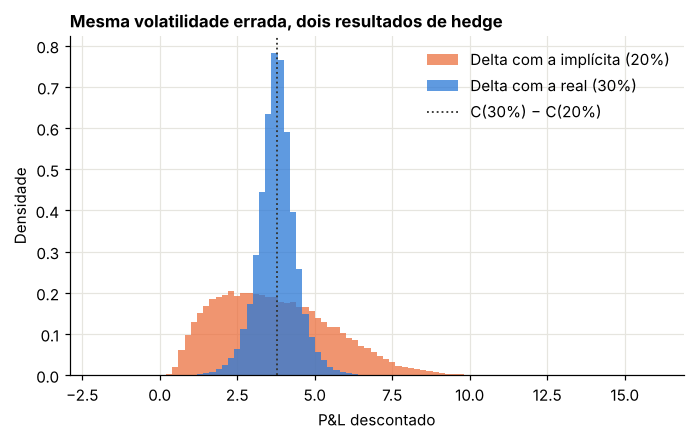

OK — com a volatilidade real, o lucro médio é C(σ_r) − C(σ_i)
OK — com a volatilidade implícita, o lucro é bem mais incerto
OK — mesmo assim, o lucro com a implícita quase sempre é positivo


In [11]:
def delta_call(S, K, tau, r, sig):
    return norm.cdf(d12(S, K, tau, r, sig)[0])


def hedge_comprado(S, K, T, r, sig_preco, sig_hedge):
    """P&L descontado de comprar a call a sig_preco e vender delta calculado com sig_hedge."""
    M = S.shape[0] - 1
    dt = T / M
    d0 = delta_call(S[0], K, T, r, sig_hedge)
    caixa = -float(bsm(S[0, 0], K, T, r, sig_preco)) + d0 * S[0]
    d_ant = d0
    for i in range(1, M):
        caixa *= np.exp(r * dt)
        novo = delta_call(S[i], K, T - i * dt, r, sig_hedge)
        caixa += (novo - d_ant) * S[i]
        d_ant = novo
    caixa *= np.exp(r * dt)
    final = caixa - d_ant * S[M] + np.maximum(S[M] - K, 0)
    return np.exp(-r * T) * final


rng = np.random.default_rng(604)
M, I = 252, 40_000
sig_i, sig_r, mu_r = 0.20, 0.30, 0.12
Z = rng.standard_normal((M, I))
S = S0 * np.exp(np.vstack([np.zeros(I), np.cumsum((mu_r - 0.5 * sig_r**2) / M + sig_r * np.sqrt(1 / M) * Z, axis=0)]))

pnl_r = hedge_comprado(S, K0, T0, r0, sig_i, sig_r)
pnl_i = hedge_comprado(S, K0, T0, r0, sig_i, sig_i)
ref = float(bsm(S0, K0, T0, r0, sig_r) - bsm(S0, K0, T0, r0, sig_i))

tabela(pd.DataFrame([
    {"Hedge": "Delta com a volatilidade real (30%)", "P&L médio": float(pnl_r.mean()), "Desvio-padrão": float(pnl_r.std(ddof=1)), "Pior caso": float(pnl_r.min()), "Melhor caso": float(pnl_r.max())},
    {"Hedge": "Delta com a volatilidade implícita (20%)", "P&L médio": float(pnl_i.mean()), "Desvio-padrão": float(pnl_i.std(ddof=1)), "Pior caso": float(pnl_i.min()), "Melhor caso": float(pnl_i.max())},
]))
print("Lucro teórico C(30%) − C(20%):", f3(ref))

faixa = (-2, 16)
fig, ax = plt.subplots()
ax.hist(pnl_i, bins=90, range=faixa, density=True, color=LARANJA, alpha=0.7, label="Delta com a implícita (20%)")
ax.hist(pnl_r, bins=90, range=faixa, density=True, color=AZUL, alpha=0.75, label="Delta com a real (30%)")
ax.axvline(ref, color="#333330", lw=1.2, ls=":", label="C(30%) − C(20%)")
ax.set_title("Mesma volatilidade errada, dois resultados de hedge")
ax.set_xlabel("P&L descontado")
ax.set_ylabel("Densidade")
ax.legend()
plt.show()

ok(abs(pnl_r.mean() - ref) < 0.05, "com a volatilidade real, o lucro médio é C(σ_r) − C(σ_i)")
ok(pnl_i.std() > 2 * pnl_r.std(), "com a volatilidade implícita, o lucro é bem mais incerto")
ok(np.mean(pnl_i > 0) > 0.95, "mesmo assim, o lucro com a implícita quase sempre é positivo")

**Leitura.** Em tempo contínuo, o hedge com a volatilidade real daria lucro exatamente constante. O desvio que resta nessa linha vem do rebalanceamento diário, o erro de $1/\sqrt{N}$ do Módulo 1. A diferença entre as duas linhas é o efeito da dependência da trajetória: as duas têm médias próximas, mas o desvio é cerca de três vezes maior com a implícita.

### 7.4 Neutralizar o gama

O erro de rebalanceamento vem do gama. Para reduzi-lo, acrescenta-se **outra opção** à carteira: escolhemos a quantidade $n$ de opção auxiliar de modo que o gama total seja zero e, depois, ajustamos o delta com o índice:

$$n = \frac{\Gamma_{\text{alvo}}}{\Gamma_{\text{aux}}}, \qquad \phi = \Delta_{\text{alvo}} - n\,\Delta_{\text{aux}}.$$

### Laboratório 7.3 — Delta contra delta-gama, com rebalanceamento semanal

Vendemos uma call de 3 meses. A auxiliar é uma call de 1 ano, com o mesmo strike.

In [12]:
def erro_hedge(S, K, T, r, sig, K_aux=None, T_aux=None):
    """Erro de hedge final de uma call vendida. Se K_aux é dado, faz delta-gama."""
    M = S.shape[0] - 1
    dt = T / M
    n_aux, phi = np.zeros(S.shape[1]), np.zeros(S.shape[1])
    caixa = np.full(S.shape[1], float(bsm(S[0, 0], K, T, r, sig)))
    for i in range(M):
        tau = T - i * dt
        s_i = S[i]
        ga, de = gregas(s_i, K, tau, r, sig)["gama"], gregas(s_i, K, tau, r, sig)["delta"]
        if K_aux is not None:
            aux = gregas(s_i, K_aux, T_aux - i * dt, r, sig)
            novo_n = ga / aux["gama"]
            novo_phi = de - novo_n * aux["delta"]
            caixa -= (novo_n - n_aux) * bsm(s_i, K_aux, T_aux - i * dt, r, sig)
            n_aux = novo_n
        else:
            novo_phi = de
        caixa -= (novo_phi - phi) * s_i
        phi = novo_phi
        caixa *= np.exp(r * dt)
    fim = caixa + phi * S[M] - np.maximum(S[M] - K, 0)
    if K_aux is not None:
        fim += n_aux * bsm(S[M], K_aux, T_aux - T, r, sig)
    return fim


rng = np.random.default_rng(605)
M, I = 13, 60_000
Z = rng.standard_normal((M, I))
S = S0 * np.exp(np.vstack([np.zeros(I), np.cumsum((0.1 - 0.5 * s0**2) * 0.25 / M + s0 * np.sqrt(0.25 / M) * Z, axis=0)]))
e_d = erro_hedge(S, K0, 0.25, r0, s0)
e_g = erro_hedge(S, K0, 0.25, r0, s0, K_aux=K0, T_aux=1.0)
tabela(pd.DataFrame([
    {"Hedge": "Só delta", "Erro médio": float(e_d.mean()), "Desvio-padrão": float(e_d.std(ddof=1))},
    {"Hedge": "Delta e gama", "Erro médio": float(e_g.mean()), "Desvio-padrão": float(e_g.std(ddof=1))},
]))
ok(e_g.std() < 0.5 * e_d.std(), "neutralizar o gama reduz o erro de hedge em mais da metade")

,Hedge,Erro médio,Desvio-padrão
0,Só delta,"-0,009","0,924"
1,Delta e gama,"-0,001","0,231"


OK — neutralizar o gama reduz o erro de hedge em mais da metade


---
## 8. Síntese

- A EDP sai da replicação: o hedge com $\Delta = V_S$ cancela o aleatório e, junto, a tendência.
- A fórmula resulta de uma integral lognormal ou da equação do calor; é a mesma conta, e Feynman-Kac explica por quê.
- $N(d_2)$ é a probabilidade de exercício sob $Q$; $N(d_1)$, sob a medida do índice.
- O teta é determinado pela EDP a partir do delta e do gama.
- Gama e teta são dois lados da mesma moeda: comprar opção com hedge é apostar em volatilidade realizada contra implícita.
- Hedge com a volatilidade certa dá lucro certo; com a implícita, dá lucro aleatório.
- A EDP numérica estende o modelo para payoffs sem fórmula.

## 9. Erratas do livro neste trecho

| Local | Problema |
|---|---|
| Passagem para (5.6) | $r(V - \partial V/\partial S)$ deveria ser $r(V - S\,\partial V/\partial S)$ |
| Equação (5.6) | falta o fator $rS$ no primeiro termo: o correto é $rS\,\partial V/\partial S$ |
| §5.2.2 | a carteira $\Pi = V - \Delta S$ não é autofinanciada; a dedução usa $\Delta$ fixo no intervalo |
| §5.2.3, item 1 | "$K > 100$ for the put, OTM" deveria ser $K < 100$ |

## 10. Exercícios

**Exercício 1.** Mostre que $V = S$ e $V = e^{rt}$ satisfazem a EDP. O que eles representam?

<details><summary>Solução</summary>

$V = S$: $V_t = 0$, $V_S = 1$, $V_{SS} = 0$, e $rS - rS = 0$. $V = e^{rt}$: $V_t = re^{rt}$, e $re^{rt} - re^{rt} = 0$. São os dois ativos negociados.
</details>

**Exercício 2.** Sem refazer contas, deduza o $\Delta$ da carteira formada por comprar uma call e vender uma put, com o mesmo strike. Por que o resultado é tão simples?

<details><summary>Solução</summary>

$\Delta_C - \Delta_P = N(d_1) - (N(d_1) - 1) = 1$. Pela paridade, a carteira equivale a um termo: $S - Ke^{-r\tau}$, com delta 1.
</details>

**Exercício 3.** Se o índice paga dividendo contínuo com taxa $y$, a EDP troca $r$ por $r - y$ no termo em $V_S$. Qual a fórmula da call?

<details><summary>Solução</summary>

$C = Se^{-y\tau}N(d_1) - Ke^{-r\tau}N(d_2)$, com $d_1 = \big[\ln(S/K) + (r - y + \tfrac12\sigma^2)\tau\big]/(\sigma\sqrt\tau)$. O índice é trocado pelo seu valor sem dividendos, $Se^{-y\tau}$.
</details>

**Exercício 4.** Deduza a condição para a qual o valor de uma call fica com $\Theta$ igual a $-rKe^{-r\tau}$ quando $\sigma \to 0$, com a opção dentro do dinheiro a termo.

<details><summary>Solução</summary>

Com $\sigma \to 0$ e $S > Ke^{-r\tau}$, temos $d_1, d_2 \to \infty$, $\varphi(d_1) \to 0$ e $N(d_2) \to 1$. Sobra $\Theta = -rKe^{-r\tau}$: a opção vale $S - Ke^{-r\tau}$, e só o desconto do strike muda com o tempo.
</details>

**Exercício 5.** Em `hedge_comprado`, faça o caso $\sigma_r < \sigma_i$ (por exemplo, compre a 30% num mundo a 20%). O que muda?

<details><summary>Solução</summary>

Os sinais se invertem: com o delta a $\sigma_r$, o prejuízo é quase determinístico e igual a $C(\sigma_r) - C(\sigma_i) < 0$. Com o delta a $\sigma_i$, o prejuízo é dependente de trajetória, em geral maior próximo do strike.
</details>

In [13]:
print(f"Módulo 5 concluído: {_checks['n']} verificações aprovadas.")

Módulo 5 concluído: 27 verificações aprovadas.
